# КП — Методи обчислювального інтелекту

Не для кожної задачі є точна формула чи алгоритм. Тоді рішення будують із нечітких правил, налаштовують за даними або шукають еволюційно. Кожна частина практикуму показує один такий метод:

| Частина | Задача | Коли беруть такий метод | Кроки |
|---|---|---|---|
| 1. Нечітка система | оцінка за словесними правилами | є знання експерта словами («якщо дохід високий і стаж середній, то…»), а даних мало | 1–4 |
| 2. Нейро-нечітка модель | прогноз виходу за даними | є дані, але потрібна модель із зрозумілими правилами, а не «чорна скринька» | 5–8 |
| 3. Генетичний алгоритм | розподіл об'єктів між бригадами | треба знайти найкращий варіант серед величезної кількості, а похідних немає і перебір неможливий | 9–11 |

Ноутбук нижче проходить кожен метод на одній задачі. Він не охоплює всіх різновидів методів (є, наприклад, модель Сугено першого порядку, інші функції належності чи оператори ГА), а частину коду дано готовою: ядро моделі Сугено, субтрактивну кластеризацію, запуск ГА, оцінку й ремонт плану, точний розв'язувач. Суть кроків — зібрати метод із заданих частин і прочитати його результат. Документація бібліотек: [scikit-fuzzy](https://scikit-fuzzy.github.io/scikit-fuzzy/) і [PyGAD](https://pygad.readthedocs.io/).

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Клітинки без `TODO` вже готові, їх лише запустити. Умова вашого варіанта — у `variants/<варіант>/README.md`, дані — у `variants/<варіант>/sample.csv`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.model_selection import train_test_split
from scipy.optimize import minimize, milp, LinearConstraint, Bounds
import pygad

## Частина 1. Нечітка система

### 1. Підсистема

Лінгвістична змінна — величина, значення якої описують словами: «низький», «середній», «високий». Кожне слово — нечітка множина з функцією належності: ступінь від 0 до 1, з яким число належить терму. Сусідні трикутні терми перекриваються, тож число належить двом термам одночасно з різними ступенями.

`automf(3, names=TERMS)` ділить діапазон на три трикутні терми з вершинами на лівому краї, посередині й на правому краї. Правило «ЯКЩО x низький І y високий ТО z середній» пов'язує терми входів із термом виходу, а таблиця 3 × 3 з README — це дев'ять таких правил.

Напишіть функцію `fuzzy_system(x_range, y_range, z_range, table, method)`, яка повертає `ctrl.ControlSystemSimulation` однієї підсистеми:

1. `x_range`, `y_range`, `z_range` — пари (min, max) з README варіанта; кожна змінна — на `np.linspace(min, max, 201)`.
2. `x` і `y` — `ctrl.Antecedent` з назвами `"x"` і `"y"`, `z` — `ctrl.Consequent` з назвою `"z"` і `defuzzify_method=method`.
3. Кожній змінній — `automf(3, names=TERMS)`.
4. `table` — таблиця правил із README як список рядків: `table[i][j]` — терм `z` для `x = TERMS[i]` і `y = TERMS[j]`. У README рядки таблиці — терми `x`, стовпці — терми `y` (заголовок «x \ y»). З неї — дев'ять правил `ctrl.Rule(x[TERMS[i]] & y[TERMS[j]], z[table[i][j]])`, з них — `ctrl.ControlSystem`.

In [6]:
TERMS = ["низький", "середній", "високий"]


def fuzzy_system(x_range, y_range, z_range, table, method):
    x = ctrl.Antecedent(np.linspace(x_range[0], x_range[1], 201), "x")
    y = ctrl.Antecedent(np.linspace(y_range[0], y_range[1], 201), "y")
    z = ctrl.Consequent(np.linspace(z_range[0], z_range[1], 201), "z", defuzzify_method=method)

    x.automf(3, names=TERMS)
    y.automf(3, names=TERMS)
    z.automf(3, names=TERMS)

    rules = []
    for i in range(3):
        for j in range(3):
            rule = ctrl.Rule(x[TERMS[i]] & y[TERMS[j]], z[table[i][j]])
            rules.append(rule)

    system = ctrl.ControlSystem(rules)
    return ctrl.ControlSystemSimulation(system)

### 2. Виведення за Мамдані

Система перетворює числа на входах у число на виході за п'ять етапів:

| Етап | Що відбувається |
|---|---|
| фазифікація | для кожного входу — ступінь належності до кожного терма |
| агрегування умов | сила правила — мінімум ступенів його умов, бо умови з'єднано «І» |
| активізація | терм виходу кожного правила зрізається на рівні сили правила |
| акумуляція | зрізані терми всіх правил об'єднуються максимумом в одну фігуру |
| дефазифікація | фігура перетворюється на число |

Центроїд — абсциса центру ваги фігури: враховує всю фігуру. Середнє максимумів — середина її найвищої ділянки: враховує лише найсильніше правило. Тому на тій самій фігурі вони дають різні числа.

1. Впишіть межі змінних і таблиці правил трьох підсистем зі свого README.
2. Порахуйте вихід 1.1 і вихід 1.2 у точці для кроку 2 з `method="centroid"`: `sim.input["x"]`, `sim.input["y"]`, `sim.compute()`, `sim.output["z"]`. «Подати входи й отримати вихід» знадобиться ще не раз, тож зробіть це функцією.
3. Подайте ці два числа на входи 1.3 — вихід 1.1 на `x`, вихід 1.2 на `y` — і порахуйте вихід 1.3 двічі: з `method="centroid"` і з `method="mom"`. 1.1 і 1.2 перераховувати не треба.
4. Виведіть виходи 1.1, 1.2 і обидва виходи 1.3.

In [7]:
# TODO: межі й таблиці трьох підсистем; виходи 1.1, 1.2 і 1.3 двома методами
table_11 = [
    ["низький", "низький", "середній"],
    ["низький", "середній", "високий"],
    ["середній", "високий", "високий"]
]
table_12 = [row.copy() for row in table_11]
table_13 = [row.copy() for row in table_11]

range_11 = ((0, 60), (-10, 20), (0, 10))
range_12 = ((0, 12), (0, 500), (0, 100))
range_13 = ((0, 10), (0, 100), (0, 8))

def calculate_fuzzy(sim, x_value, y_value):
    sim.input["x"] = x_value
    sim.input["y"] = y_value

    sim.compute()

    return sim.output["z"]

sim_11 = fuzzy_system(*range_11, table_11, "centroid")

z11 = calculate_fuzzy(sim_11, 33, 18.5)

sim_12 = fuzzy_system(*range_12, table_12, "centroid")

z12 = calculate_fuzzy(sim_12, 10.2, 300)

print(f"1.1 - snow thaw speed: {z11:.3f} cm/day")
print(f"1.2 - water recede volume: {z12:.3f} million m^3")


sim_13_centroid = fuzzy_system(*range_13, table_13, "centroid")

z13_centroid = calculate_fuzzy(sim_13_centroid, z11, z12)

sim_13_mom = fuzzy_system(*range_13, table_13, "mom")

z13_mom = calculate_fuzzy(sim_13_mom, z11, z12)

print(f"1.3 - centroid: {z13_centroid:.3f} m")
print(f"1.3 - mom: {z13_mom:.3f} m")
print(f"difference: {abs(z13_centroid - z13_mom):.3f} m")



1.1 - snow thaw speed: 7.382 cm/day
1.2 - water recede volume: 62.439 million m^3
1.3 - centroid: 4.431 m
1.3 - mom: 4.000 m
difference: 0.431 m


Щоб побачити, чому методи дали різні числа, подивіться, які правила 1.3 спрацювали в цій точці.

Виведіть силу кожного з дев'яти правил 1.3 за таблицею з README, від більшої до меншої. Входи 1.3 — виходи 1.1 і 1.2 з попередньої клітинки.

- ступінь належності входу до терма — `fuzz.interp_membership(universe, mf, значення)`;
- трикутники `automf` — `fuzz.trimf(universe, [a, a, m])`, `[a, m, b]` і `[m, b, b]`, де `a` і `b` — межі змінної, `m` — середина;
- сила правила — мінімум ступенів `x` і `y`; правила із силою 0 не спрацювали.

In [ ]:
# TODO: сила дев'яти правил 1.3 у цій точці
x_var, y_var = list(sim_13_centroid.ctrl.antecedents)

x_memberships = {}
y_memberships = {}

for term in TERMS:
    x_memberships[term] = fuzz.interp_membership(x_var.universe, x_var[term].mf, z11)
    y_memberships[term] = fuzz.interp_membership(y_var.universe, y_var[term].mf, z12)

print("Snow melting memberships:", x_memberships)
print("Water recede memberships:", y_memberships)

rule_results = []

for i in range(3):
    for j in range(3):
        strength = min(x_memberships[TERMS[i]], y_memberships[TERMS[j]])
        rule_results.append({
            "snow_melting": TERMS[i],
            "water_recede": TERMS[j],
            "output": table_13[i][j],
            "strength": strength
        })

rules_df = pd.DataFrame(rule_results)
rules_df = rules_df.sort_values("strength", ascending=False)

display(rules_df.round(3))

Snow melting memberships: {'низький': np.float64(0.0), 'середній': np.float64(0.523529411764706), 'високий': np.float64(0.47647058823529403)}
Water recede memberships: {'низький': np.float64(0.0), 'середній': np.float64(0.7512141280353216), 'високий': np.float64(0.24878587196467833)}


,snow_melting,water_release,output,strength
4,середній,середній,середній,0.524
7,високий,середній,високий,0.476
5,середній,високий,високий,0.249
8,високий,високий,високий,0.249
0,низький,низький,низький,0.000
3,середній,низький,низький,0.000
2,низький,високий,середній,0.000
1,низький,середній,низький,0.000
6,високий,низький,середній,0.000


### 3. Поверхня

Поверхня показує вихід підсистеми для всіх пар входів одразу. Пологі ділянки — зони, де переважає одне правило; схили — переходи між правилами.

Побудуйте поверхню підсистеми 1.3: вихід (центроїд) на сітці 21 × 21 значень `x` і `y` у їхніх межах. Намалюйте її як `plt.contourf` або 3D-поверхню й підпишіть осі назвами змінних. `plt.contourf(xs, ys, Z)` чекає `Z[i, j]` для `y = ys[i]` і `x = xs[j]`. Зробіть це функцією від таблиці правил: у кроці 4 таку саму поверхню треба побудувати для зміненої таблиці.

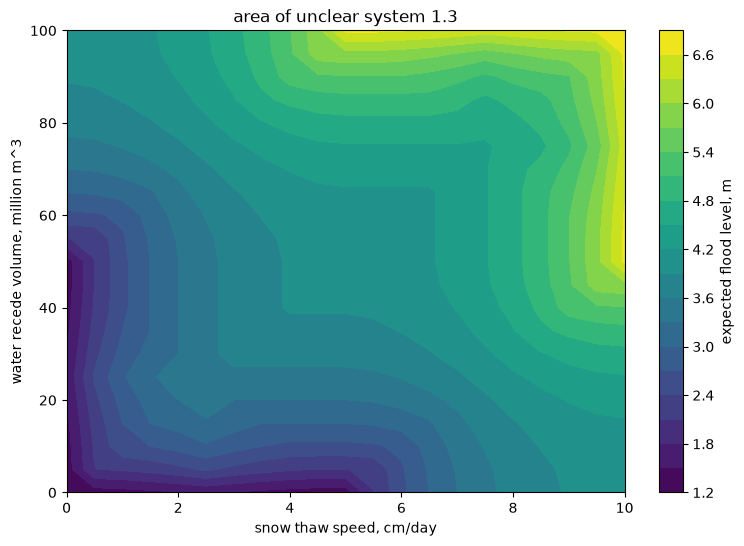

In [9]:
# TODO: поверхня 1.3

xs = np.linspace(0, 10, 21)
ys = np.linspace(0, 100, 21)

def fuzzy_surface(table):
    Z = np.zeros((len(ys), len(xs)))
    sim = fuzzy_system(*range_13, table, "centroid")

    for i in range(len(ys)):
        for j in range(len(xs)):
            Z[i, j] = calculate_fuzzy(sim, xs[j], ys[i])

    return Z

Z_original = fuzzy_surface(table_13)

plt.figure(figsize=(9, 6))
plt.contourf(xs, ys, Z_original, levels=20, cmap="viridis")
plt.colorbar(label="expected flood level, m")
plt.xlabel("snow thaw speed, cm/day")
plt.ylabel("water recede volume, million m^3")
plt.title("area of unclear system 1.3")
plt.show()


### 4. Одне правило

Кожне правило керує виходом лише там, де воно спрацьовує. Тому зміна однієї клітинки таблиці — одного правила — змінює поверхню лише там, де сила цього правила більша за 0. Для правила з крайніми термами це кут поверхні, для правила із середніми термами — більша її частина, бо середній терм покриває весь діапазон, крім країв.

1. Змініть правило 1.3, як сказано в README для кроку 4. Змінюйте копію таблиці (`[row[:] for row in table]`): стара ще потрібна для порівняння, а зміна вкладеного списку на місці зачепить і її.
2. Порахуйте вихід 1.3 у тій самій точці з `method="centroid"` і з `method="mom"` та виведіть поруч зі старими.
3. Побудуйте поверхню зі зміненим правилом і різницю двох поверхонь.

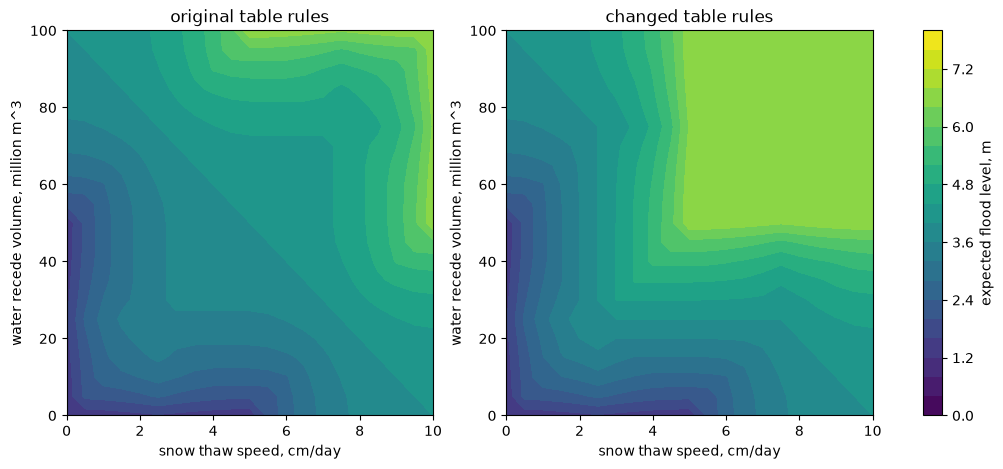

In [11]:
# TODO: змінене правило, вихід 1.3 і поверхні
table_13_changed = [row.copy() for row in table_13]
table_13_changed[1][1] = "високий"

Z_changed = fuzzy_surface(table_13_changed)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].contourf(xs, ys, Z_original, levels=np.linspace(0, 8, 21), cmap="viridis")
axes[0].set_title("original table rules")

im = axes[1].contourf(xs, ys, Z_changed, levels=np.linspace(0, 8, 21), cmap="viridis")
axes[1].set_title("changed table rules")

for ax in axes:
    ax.set_xlabel("snow thaw speed, cm/day")
    ax.set_ylabel("water recede volume, million m^3")

fig.colorbar(im, ax=axes, label="expected flood level, m")
plt.show()


## Частина 2. Нейро-нечітка модель

### 5. Дані

Модель Сугено нульового порядку складається з правил «ЯКЩО входи близькі до центру правила ТО y = число». Вихід — середнє висновків правил, зважене ступенями активації. Нейро-нечіткою її роблять параметри — центри, ширини й висновки, — які підбирають за даними, як ваги мережі.

Похибка — RMSE в одиницях виходу. Точка відліку — прогноз середнім значенням навчальної частини: модель, гірша за нього на тестовій частині, нічого корисного не навчилася. Входи й вихід нормують у [0, 1] за навчальною частиною, щоб центри й ширини правил мали однаковий масштаб.

1. Завантажте `sample.csv` свого варіанта: `X` — усі колонки, крім останньої, `y` — остання. Поділ задано нижче.
2. Нормуйте мінімумом і максимумом навчальної частини, для кожного входу окремо (`X_tr.min(axis=0)`): `x_tr`, `x_te` — входи, `t_tr`, `t_te` — вихід. Для тестової частини теж беруть мінімум і максимум навчальної, тож її значення можуть трохи виходити за [0, 1] — це нормально.
3. `y_span = y_tr.max() - y_tr.min()`: на нього множать нормовану похибку, щоб отримати одиниці виходу.
4. Виведіть розміри частин і RMSE прогнозу середнім `y_tr` на навчальній і тестовій частинах.

In [12]:
# TODO: sample.csv свого варіанта, X і y
sample = pd.read_csv("sample.csv")

X = sample[["reactive_energy_mvarh", "heat_energy_gcal", "contracted_power_kw", "outage_hours"]]
y = sample["service_cost_kuah"]

X_tr, X_te, y_tr, y_te = train_test_split(X.to_numpy(), y.to_numpy(), test_size=0.25, random_state=0)

# TODO: x_tr, x_te, t_tr, t_te, y_span і RMSE прогнозу середнім
x_min = X_tr.min(axis=0)
x_span = X_tr.max(axis=0) - x_min
x_span[x_span == 0] = 1

x_tr = (X_tr - x_min) / x_span
x_te = (X_te - x_min) / x_span

y_min = y_tr.min()
y_span = y_tr.max() - y_min

t_tr = (y_tr - y_min) / y_span
t_te = (y_te - y_min) / y_span

mean_prediction = np.mean(y_tr)

rmse_tr = np.sqrt(np.mean((y_tr - mean_prediction) ** 2))
rmse_te = np.sqrt(np.mean((y_te - mean_prediction) ** 2))

print("Sample:", sample.shape)
print("Train:", x_tr.shape)
print("Test:", x_te.shape)
print(f"RMSE mean train: {rmse_tr:.3f} thousand UAH")
print(f"RMSE mean test: {rmse_te:.3f} thousand UAH")

Sample: (60, 5)
Train: (45, 4)
Test: (15, 4)
RMSE mean train: 1.125 thousand UAH
RMSE mean test: 0.861 thousand UAH


In [13]:
def unpack(theta, c):
    k = c * x_tr.shape[1]
    return theta[:k].reshape(c, -1), np.exp(theta[k:2 * k]).reshape(c, -1), theta[2 * k:]


def activation(theta, x, c):
    centers, widths, _ = unpack(theta, c)
    z = -0.5 * (((x[:, None, :] - centers[None]) / widths[None]) ** 2).sum(axis=2)
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def rmse(theta, x, t, c):
    return float(np.sqrt(np.mean((activation(theta, x, c) @ unpack(theta, c)[2] - t) ** 2)))


def errors(theta, c):
    return rmse(theta, x_tr, t_tr, c) * y_span, rmse(theta, x_te, t_te, c) * y_span


def pack(centers, widths):
    c = len(centers)
    theta = np.concatenate([np.ravel(centers), np.log(np.ravel(widths)), np.zeros(c)])
    w = activation(theta, x_tr, c)
    theta[2 * c * x_tr.shape[1]:] = np.linalg.solve(w.T @ w + 1e-8 * np.eye(c), w.T @ t_tr)
    return theta


def tune(theta, c):
    n = c * x_tr.shape[1]
    bounds = [(-0.05, 1.05)] * n + [(np.log(0.08), np.log(0.8))] * n + [(-0.05, 1.05)] * c
    res = minimize(rmse, np.clip(theta, *np.array(bounds).T), args=(x_tr, t_tr, c),
                   method="L-BFGS-B", bounds=bounds, options={"maxiter": 2000})
    return res.x

Що робить готовий код вище:

| Функція | Що робить |
|---|---|
| `activation` | ступені активації правил: гаусова функція належності на кожен вхід, добуток по входах, нормування до суми 1 (обчислюється через експоненту різниці, щоб не ділити на машинний нуль) |
| `pack` | збирає параметри правил в один вектор; висновки правил рахує методом найменших квадратів, як прямий хід ANFIS |
| `tune` | налаштовує всі параметри мінімізацією RMSE на навчальній частині; центри не виходять за межі даних, ширина — від 0.08 до 0.8 діапазону |
| `errors` | RMSE на навчальній і тестовій частинах в одиницях виходу |

### 6. Субтрактивна кластеризація

Щоб отримати правила з даних, точки навчальної частини кластеризують: кожен кластер стає правилом. Субтрактивна кластеризація сама визначає, скільки кластерів. Кожна точка отримує потенціал — скільки інших точок поблизу. Точка з найбільшим потенціалом стає центром, потенціал її сусідів у межах радіуса впливу `ra` зменшується, і пошук повторюється, доки потенціал не впаде нижче порогу. Малий радіус — багато дрібних кластерів, великий — кілька великих. Так будує базу правил редактор ANFIS у Matlab.

Субтрактивна кластеризація сама обирає кількість правил, але ця кількість сильно залежить від `ra`, а яке `ra` правильне, метод не підказує. Тому далі правила будує c-means із заданою кількістю, а в кроці 8 перевіряють, скільки правил справді потрібно.

Для `ra` = 0.3, 0.5 і 0.8 запустіть `subclust` на `np.column_stack([x_tr, t_tr])` і виведіть, скільки правил дає кожен радіус — стільки рядків у результаті.

In [14]:
def subclust(data, ra, accept=0.5, reject=0.15):
    a, b = 4 / ra ** 2, 4 / (1.5 * ra) ** 2
    potential = np.exp(-a * ((data[:, None, :] - data[None, :, :]) ** 2).sum(-1)).sum(1)
    first, centers = potential.max(), []
    while True:
        k = int(potential.argmax())
        top = potential[k]
        if top < reject * first:
            break
        if top < accept * first:
            nearest = min(np.sqrt(((data[k] - data[c]) ** 2).sum()) for c in centers)
            if nearest / ra + top / first < 1:
                potential[k] = 0
                continue
        centers.append(k)
        potential = np.maximum(potential - top * np.exp(-b * ((data - data[k]) ** 2).sum(1)), 0)
    return data[centers]

In [15]:
# TODO: скільки правил дає кожен ra

data = np.column_stack([x_tr, t_tr])

for ra in [0.3, 0.5, 0.8]:
    centers = subclust(data, ra)
    print(f"ra = {ra}: {len(centers)} rules")


ra = 0.3: 19 rules
ra = 0.5: 8 rules
ra = 0.8: 2 rules


### 7. Правила з c-means і налаштування

Нечітка кластеризація c-means не визначає кількість кластерів сама: її задають. Зате кожна точка належить кожному кластеру зі своїм ступенем `u`. Кластеризують разом входи й вихід, бо правило має об'єднувати точки, схожі і за входами, і за виходом. Центр правила — перші координати центру кластера, тобто вхідні; ширина на кожен вхід — стандартне відхилення точок від центру, зважене квадратами ступенів `u`.

Налаштування підганяє центри, ширини й висновки під навчальну частину. У трьох правил на чотири входи 27 параметрів, а навчальних рядків — кілька десятків. Такій моделі легко запам'ятати навчальні точки разом із їхнім шумом.

1. Функція `cmeans_rules(c)` нижче майже готова: допишіть ширини. Ширина правила `k` на кожен вхід — `np.sqrt((u[k] ** 2 @ (x_tr - centers[k]) ** 2) / (u[k] ** 2).sum())`.
2. Побудуйте три правила `theta = cmeans_rules(3)` і налаштуйте їх: `theta_tuned = tune(theta, 3)`.
3. Виведіть таблицю RMSE на навчальній і тестовій частинах: прогноз середнім, правила до налаштування (`errors(theta, 3)`) і після.

In [16]:
def cmeans_rules(c):
    cntr, u, *_ = fuzz.cluster.cmeans(np.column_stack([x_tr, t_tr]).T, c=c, m=2.0, error=1e-6, maxiter=1000, seed=0)
    centers = cntr[:, :x_tr.shape[1]]
    widths = np.zeros_like(centers)

    for k in range(c):
        widths[k] = np.sqrt((u[k] ** 2 @ (x_tr - centers[k]) ** 2) / (u[k] ** 2).sum())

    return pack(centers, np.clip(widths, 0.08, 0.8))


# TODO: theta, theta_tuned і таблиця RMSE
theta = cmeans_rules(3)
theta_tuned = tune(theta, 3)

rmse_before = errors(theta, 3)
rmse_after = errors(theta_tuned, 3)

mean_train = np.sqrt(np.mean((y_tr - y_tr.mean()) ** 2))
mean_test = np.sqrt(np.mean((y_te - y_tr.mean()) ** 2))

results_df = pd.DataFrame({
    "model": ["Mean prediction", "C-means before tuning", "C-means after tuning"],
    "RMSE train": [mean_train, rmse_before[0], rmse_after[0]],
    "RMSE test": [mean_test, rmse_before[1], rmse_after[1]]
})

display(results_df.round(3))



,model,RMSE train,RMSE test
0,Mean prediction,1.125,0.861
1,C-means before tuning,1.056,0.638
2,C-means after tuning,0.691,1.201


### 8. Кількість правил

Кожне нове правило додає параметри. Навчальна похибка від цього зазвичай спадає, а тестова — лише доки нові правила описують закономірність, а не шум. Що більший розрив між тестовою і навчальною похибкою, то сильніше перенавчання.

Для кількості правил від 2 до 6 побудуйте правила `cmeans_rules(c)` і налаштуйте їх. Виведіть таблицю «кількість правил, RMSE на навчальній і тестовій частинах» і побудуйте обидві криві на одному графіку разом із горизонтальною лінією RMSE прогнозу середнім на тестовій частині. Налаштування може зупинитися в локальному мінімумі, тож на кількох десятках рядків криві бувають нерівними; порівнюйте розрив при 2 і при 6 правилах. `theta` і `theta_tuned` із кроку 7 не перезаписуйте: їх використовує самоперевірка.

,rules,RMSE train,RMSE test,difference
0,2,0.823,0.598,-0.225
1,3,0.691,1.201,0.510
2,4,0.574,0.928,0.354
3,5,0.439,1.210,0.771
4,6,0.292,1.053,0.761


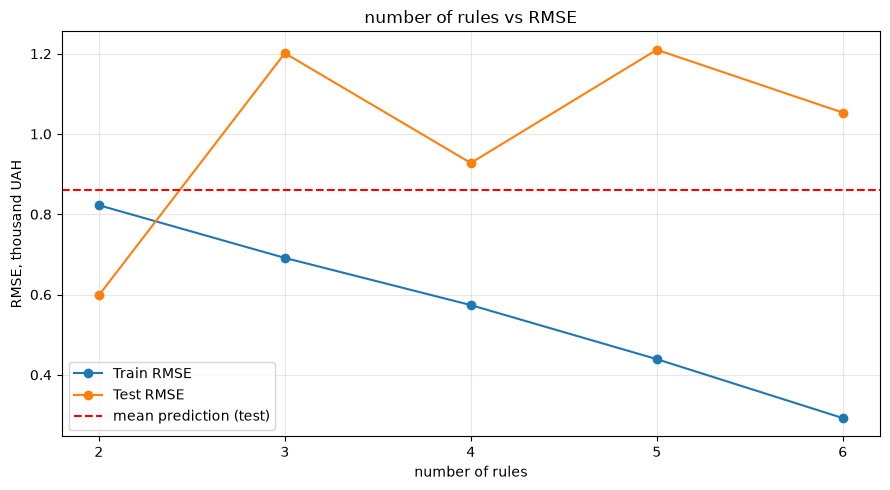

In [20]:
# TODO: таблиця й криві для 2–6 правил
results = []

for c in range(2, 7):
    theta_c = cmeans_rules(c)
    theta_c_tuned = tune(theta_c, c)
    rmse_train, rmse_test = errors(theta_c_tuned, c)

    results.append({"rules": c, "RMSE train": rmse_train, "RMSE test": rmse_test, "difference": rmse_test - rmse_train})

rules_df = pd.DataFrame(results)
display(rules_df.round(3))


plt.figure(figsize=(9, 5))

plt.plot(rules_df["rules"], rules_df["RMSE train"], marker="o", label="Train RMSE")
plt.plot(rules_df["rules"], rules_df["RMSE test"], marker="o", label="Test RMSE")

plt.axhline(mean_test, color="red", linestyle="--", label="mean prediction (test)")

plt.xlabel("number of rules")
plt.ylabel("RMSE, thousand UAH")
plt.title("number of rules vs RMSE")
plt.xticks(range(2, 7))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



## Частина 3. Розподіл бригад

### 9. Задача й жадібний алгоритм

Об'єкти — рядки `sample.csv`. Кожен об'єкт можна доручити одній із трьох бригад або не брати в план. Час на об'єкт і фонд часу бригад — у README варіанта, втрати, яких уникає обслуговування, — остання колонка. Треба максимізувати суму втрат, яких уникнули, так, щоб жодна бригада не вийшла за свій фонд. Це задача про кілька рюкзаків: перебором її не розв'язати, бо варіантів плану 4 в степені кількості об'єктів.

Жадібний алгоритм бере об'єкти за спаданням відношення «втрати / час» і кладе кожен у першу бригаду, де він ще вміщується, перевіряючи бригади 1, 2, 3 по черзі. Він швидкий, але може зайняти місце, яке краще було б віддати двом іншим об'єктам.

План записується як масив: для кожного об'єкта 0 — не обслуговувати, 1–3 — номер бригади.

1. Впишіть фонд часу трьох бригад і дільник із README варіанта. Порахуйте `t = 0.5 + contracted_power_kw / TIME_DIV` для кожного рядка `sample`; `v` — остання колонка. Беріть усі рядки `sample.csv`, а не лише навчальну частину з кроку 5.
2. Складіть план жадібним алгоритмом, назвіть його `plan_greedy` і виведіть суму, завантаження й перевищення. Порядок об'єктів за спаданням `v / t` дає `np.argsort(-(v / t))`.

Функції нижче вже готові: `load` — завантаження бригад, `overflow` — сумарне перевищення фондів, `value` — сума плану, `repair` — ремонт плану.

In [21]:
# TODO: FUND, TIME_DIV, t і v
FUND = (9, 6, 3)
TIME_DIV = 12

t = 0.5 + sample["contracted_power_kw"].to_numpy() / TIME_DIV
v = sample["service_cost_kuah"].to_numpy()

print("Objects:", len(t))
print("Total available hours:", sum(FUND))
print("Total potential value:", round(v.sum(), 3), "thousand UAH")

display(pd.DataFrame({"time": t, "value": v, "value_per_hour": v / t}).head())

Objects: 60
Total available hours: 18
Total potential value: 119.409 thousand UAH


,time,value,value_per_hour
0,1.281250,2.250,1.756098
1,1.056083,0.317,0.300166
2,1.144833,1.907,1.665745
3,1.343750,4.746,3.531907
4,1.152000,0.375,0.325521


In [22]:
def load(plan):
    return [float(t[plan == b].sum()) for b in (1, 2, 3)]


def overflow(plan):
    return float(sum(max(0.0, used - f) for used, f in zip(load(plan), FUND)))


def value(plan):
    return float(v[plan > 0].sum())


def repair(plan):
    plan = np.asarray(plan, int).copy()
    for b, f in enumerate(FUND, start=1):
        idx = np.flatnonzero(plan == b)
        used = t[idx].sum()
        for i in idx[np.argsort(v[idx] / t[idx])]:
            if used <= f + 1e-9:
                break
            plan[i], used = 0, used - t[i]
    return plan

In [24]:

plan_greedy = np.zeros(len(t), dtype=int)

for i in np.argsort(-(v / t)):
    for b in range(3):
        if load(plan_greedy)[b] + t[i] <= FUND[b] + 1e-9:
            plan_greedy[i] = b + 1
            break

print("greedy value:", round(value(plan_greedy), 3), "thousand UAH")
print("brigade load:", np.round(load(plan_greedy), 3))
print("overflow:", round(overflow(plan_greedy), 3), "hours")
print("selected objects:", np.count_nonzero(plan_greedy))

greedy value: 34.829 thousand UAH
brigade load: [8.339 5.668 2.814]
overflow: 0.0 hours
selected objects: 11


### 10. Генетичний алгоритм

Генетичний алгоритм тримає популяцію планів. Кожен план оцінюється пристосованістю. Турнірна селекція відбирає кращих із випадкових трійок, рівномірне схрещування бере кожен ген від одного з двох батьків, мутація випадково змінює кілька генів, а чотири найкращі плани переходять у нове покоління без змін. Похідні не потрібні — досить уміти оцінити план.

Обмеження фонду в суму не входить, тож із ним поводяться окремо:

| Спосіб | Як | Ризик |
|---|---|---|
| штраф | пристосованість = сума − 10 · перевищення | малий виступ за фонд може окупитися, і найкращий план буде недопустимим |
| ремонт | перед оцінкою з переповненої бригади знімають найменш вигідні об'єкти; оцінюють уже допустимий план | пошук іде лише серед того, що вміє полагодити ремонт |

Функція `run_ga(fitness)` нижче запускає ГА з параметрами практикуму й повертає найкращий план. Функція пристосованості для `pygad` має вигляд `lambda ga, sol, idx: ...`.

1. ГА з ремонтом: пристосованість — `value(repair(sol))`. Найкращий план полагодьте `repair` і назвіть `plan_repair`.
2. ГА зі штрафом: пристосованість — `value(sol) - 10 * overflow(sol)`. Найкращий план назвіть `plan_penalty`, без ремонту.
3. Для обох планів виведіть суму, завантаження й перевищення.

In [25]:
def run_ga(fitness):
    ga = pygad.GA(num_generations=250, sol_per_pop=120, num_parents_mating=60, num_genes=len(t), gene_type=int,
                  gene_space=[0, 1, 2, 3], fitness_func=fitness, parent_selection_type="tournament", K_tournament=3,
                  crossover_type="uniform", mutation_type="random", mutation_num_genes=max(1, len(t) // 20),
                  keep_elitism=4, random_seed=0, suppress_warnings=True)
    ga.run()
    return np.asarray(ga.best_solution()[0], int)



def repair(plan):
    plan = np.asarray(plan, dtype=int).copy()

    for b in range(1, 4):
        while load(plan)[b - 1] > FUND[b - 1] + 1e-9:
            indices = np.where(plan == b)[0]
            worst = indices[np.argmin(v[indices] / t[indices])]
            plan[worst] = 0

    return plan

plan_repair = run_ga(lambda ga, sol, idx: value(repair(sol)))
plan_repair = repair(plan_repair)

print("GA repair value:", round(value(plan_repair), 3), "thousand UAH")
print("brigade load:", np.round(load(plan_repair), 3))
print("overflow:", round(overflow(plan_repair), 3), "hours")
print("selected objects:", np.count_nonzero(plan_repair))


GA repair value: 36.471 thousand UAH
brigade load: [8.994 5.932 2.987]
overflow: 0.0 hours
selected objects: 11


In [ ]:
# TODO: plan_penalty

plan_penalty = run_ga(lambda ga, sol, idx: value(sol) - 10 * overflow(sol))

print("GA penalty value:", round(value(plan_penalty), 3), "thousand UAH")
print("brigade load:", np.round(load(plan_penalty), 3))
print("overflow:", round(overflow(plan_penalty), 3), "hours")
print("selected objects:", np.count_nonzero(plan_penalty))


GA penalty value: 27.584 thousand UAH
Brigade load: [7.312 5.363 3.006]
Overflow: 0.006 hours
Selected objects: 11


### 11. Точний оптимум

Для кількох десятків об'єктів задачу можна розв'язати точно цілочисловим лінійним програмуванням. Готова функція нижче повертає найкращий можливий план. На практиці такий розв'язувач є не завжди, а в більших задачах він не встигає — тоді й беруть ГА.

Порахуйте `plan_optimum = optimum()` і виведіть таблицю: жадібний алгоритм, ГА з ремонтом, ГА зі штрафом, оптимум — сума, завантаження бригад, перевищення і сума у відсотках від оптимуму.

In [27]:
def optimum():
    n = len(t)
    rows = [np.concatenate([t if b == k else np.zeros(n) for k in range(3)]) for b in range(3)]
    rows += [np.tile(np.eye(n)[i], 3) for i in range(n)]
    res = milp(-np.tile(v, 3), integrality=np.ones(3 * n), bounds=Bounds(0, 1),
               constraints=LinearConstraint(np.array(rows), [0] * (3 + n), list(FUND) + [1] * n))
    return (np.arange(1, 4)[:, None] * np.round(res.x).reshape(3, n)).sum(0).astype(int)

In [29]:
# TODO: plan_optimum і таблиця чотирьох планів
plan_optimum = optimum()

plans = {
    "Greedy": plan_greedy,
    "GA repair": plan_repair,
    "GA penalty": plan_penalty,
    "Optimum": plan_optimum
}

optimum_value = value(plan_optimum)
results = []

for name, plan in plans.items():
    results.append({
        "Plan": name,
        "Value": value(plan),
        "Brigade load": np.round(load(plan), 3),
        "Overflow": overflow(plan),
        "% optimum": 100 * value(plan) / optimum_value
    })

comparison_df = pd.DataFrame(results)
display(comparison_df.round(6))

,Plan,Value,Brigade load,Overflow,% optimum
0,Greedy,34.829,"[8.339, 5.668, 2.814]",0.000000,95.497793
1,GA repair,36.471,"[8.994, 5.932, 2.987]",0.000000,100.000000
2,GA penalty,27.584,"[7.312, 5.363, 3.006]",0.005667,75.632694
3,Optimum,36.471,"[8.996, 5.957, 2.961]",0.000000,100.000000


### 12. Самоперевірка й збереження

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [30]:
plan = pd.DataFrame({"row": np.arange(len(t)), "brigade": np.asarray(plan_repair, int)})

assert len(t) == len(v) == len(plan) == len(sample), "t, v і план мають мати рядок на кожен об'єкт sample.csv"
assert tuple(FUND) in [(6, 6, 6), (7, 6, 5), (7, 7, 4), (8, 5, 5), (8, 6, 4), (8, 7, 3), (9, 5, 4), (9, 6, 3), (10, 4, 4), (10, 5, 3)] and TIME_DIV in (8, 10, 12), "фонди бригад і дільник — з README варіанта, фонди в порядку бригад 1, 2, 3"
assert plan["brigade"].isin([0, 1, 2, 3]).all(), "бригада — 0, 1, 2 або 3"
assert overflow(plan_repair) == 0, "план ГА з ремонтом перевищує фонд часу"
assert value(plan_repair) >= value(plan_greedy) - 1e-9, "ГА з ремонтом гірший за жадібний алгоритм: перевірте параметри з кроку 10"
assert value(plan_repair) <= value(plan_optimum) + 1e-9, "сума більша за оптимум: перевірте t, v і FUND"
assert errors(theta_tuned, 3)[0] < errors(theta, 3)[0], "налаштування не знизило навчальну похибку"

plan.to_csv("plan.csv", index=False)
print("усе гаразд: сума", round(value(plan_repair), 3), "з оптимуму", round(value(plan_optimum), 3))

усе гаразд: сума 36.471 з оптимуму 36.471
